# Task 3 — Prediction Model: Breast Cancer Classification
**CodeNova AI/ML Internship · Batch 01**

## Objective
Build and evaluate a classification model, compare it with a baseline, use cross-validation, and explain limitations.

## Dataset
The Wisconsin Diagnostic Breast Cancer dataset distributed by scikit-learn. Target encoding: **malignant = 0**, **benign = 1**. The included CSV makes the notebook runnable offline.

## Methodology
- Keep a stratified held-out test set separate from model selection.
- Compare a majority-class dummy baseline, standardized Logistic Regression, and Random Forest.
- Use 5-fold stratified cross-validation on training data to select a non-baseline model by F1.
- Report accuracy, precision, recall, F1, ROC-AUC, confusion matrix, ROC curve, and feature importance.
- Keep scaling inside a pipeline to prevent leakage.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,
 ConfusionMatrixDisplay,RocCurveDisplay,classification_report)
BASE=Path("..")
df=pd.read_csv(BASE/"data"/"breast_cancer_dataset.csv")
print("Dataset shape:",df.shape)
display(df.head())
display(df["target_name"].value_counts().to_frame("count"))

Dataset shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


,count
target_name,
benign,357
malignant,212


## 1. Data preparation and split
A stratified 80/20 split keeps class proportions similar in training and test sets. The test set is not used for cross-validation or model selection.

In [2]:
X=df.drop(columns=["target","target_name"]); y=df["target"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42,stratify=y)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
display(y_train.map({0:"malignant",1:"benign"}).value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 455 | Test rows: 114


,proportion
target,
benign,0.626374
malignant,0.373626


## 2. Models and cross-validation
Scaling is fitted only inside the Logistic Regression pipeline. Random Forest does not require feature scaling. The dummy classifier is a simple baseline.

In [3]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
models={
 "Dummy baseline":DummyClassifier(strategy="most_frequent"),
 "Logistic Regression":Pipeline([("scaler",StandardScaler()),("model",LogisticRegression(max_iter=5000,class_weight="balanced",random_state=42))]),
 "Random Forest":RandomForestClassifier(n_estimators=300,random_state=42,class_weight="balanced",min_samples_leaf=2,n_jobs=-1)
}
rows=[]
for name,model in models.items():
 scores=cross_val_score(model,X_train,y_train,cv=cv,scoring="f1")
 rows.append({"model":name,"cv_f1_mean":scores.mean(),"cv_f1_std":scores.std()})
cv_results=pd.DataFrame(rows).sort_values("cv_f1_mean",ascending=False)
display(cv_results.round(4))

,model,cv_f1_mean,cv_f1_std
1,Logistic Regression,0.9805,0.0105
2,Random Forest,0.9663,0.0145
0,Dummy baseline,0.7703,0.0000


## 3. Model selection and held-out evaluation
Select the highest mean cross-validation F1 among non-baseline models, refit it on the complete training partition, and evaluate it once on the held-out test partition.

In [4]:
best_name=cv_results[cv_results.model!="Dummy baseline"].iloc[0].model
best_model=models[best_name]; best_model.fit(X_train,y_train)
y_pred=best_model.predict(X_test); y_score=best_model.predict_proba(X_test)[:,1]
metrics={"selected_model":best_name,"accuracy":accuracy_score(y_test,y_pred),
 "precision_benign":precision_score(y_test,y_pred,pos_label=1,zero_division=0),
 "recall_benign":recall_score(y_test,y_pred,pos_label=1,zero_division=0),
 "f1_benign":f1_score(y_test,y_pred,pos_label=1,zero_division=0),
 "roc_auc_benign":roc_auc_score(y_test,y_score)}
display(pd.DataFrame([metrics]).T.rename(columns={0:"value"}).round(4))
print(classification_report(y_test,y_pred,target_names=["malignant","benign"],zero_division=0))

,value
selected_model,Logistic Regression
accuracy,0.95614
precision_benign,0.985507
recall_benign,0.944444
f1_benign,0.964539
roc_auc_benign,0.99537


              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



## 4. Confusion matrix
The confusion matrix shows class-specific errors. For a medical dataset, false negatives and false positives have different implications, so accuracy alone is not sufficient.

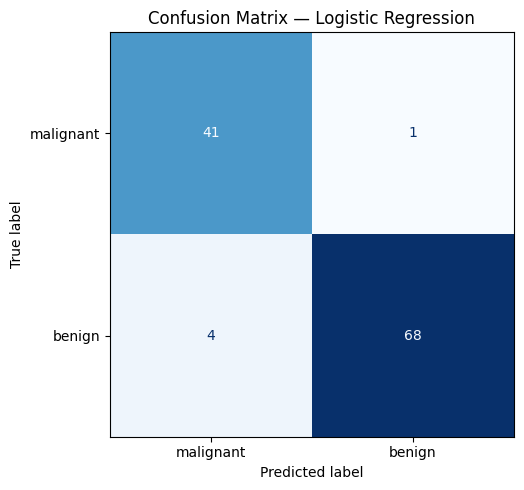

In [5]:
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=["malignant","benign"],cmap="Blues",ax=ax,colorbar=False)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout(); plt.show()

## 5. ROC curve
ROC-AUC measures ranking quality across thresholds. It does not choose the best operational threshold by itself.

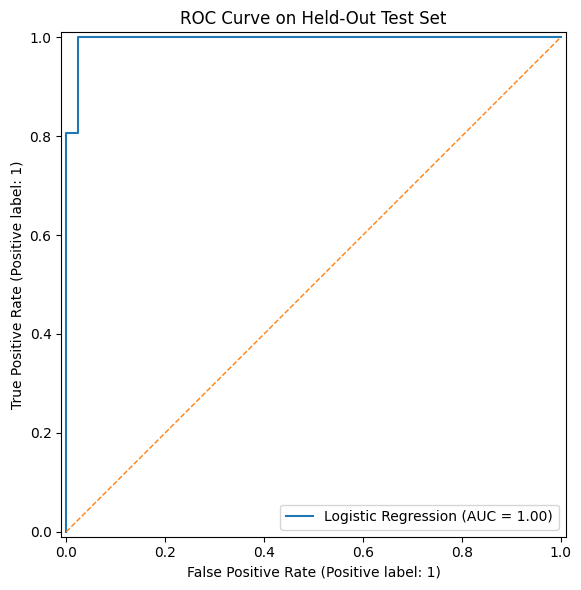

In [6]:
fig,ax=plt.subplots(figsize=(7,6))
RocCurveDisplay.from_predictions(y_test,y_score,ax=ax,name=best_name)
ax.plot([0,1],[0,1],linestyle="--",linewidth=1,label="Random baseline")
ax.set_title("ROC Curve on Held-Out Test Set")
plt.tight_layout(); plt.show()

## 6. Feature importance
For Logistic Regression, absolute coefficient magnitudes after standardization are displayed. These are model associations, not proof of causation.

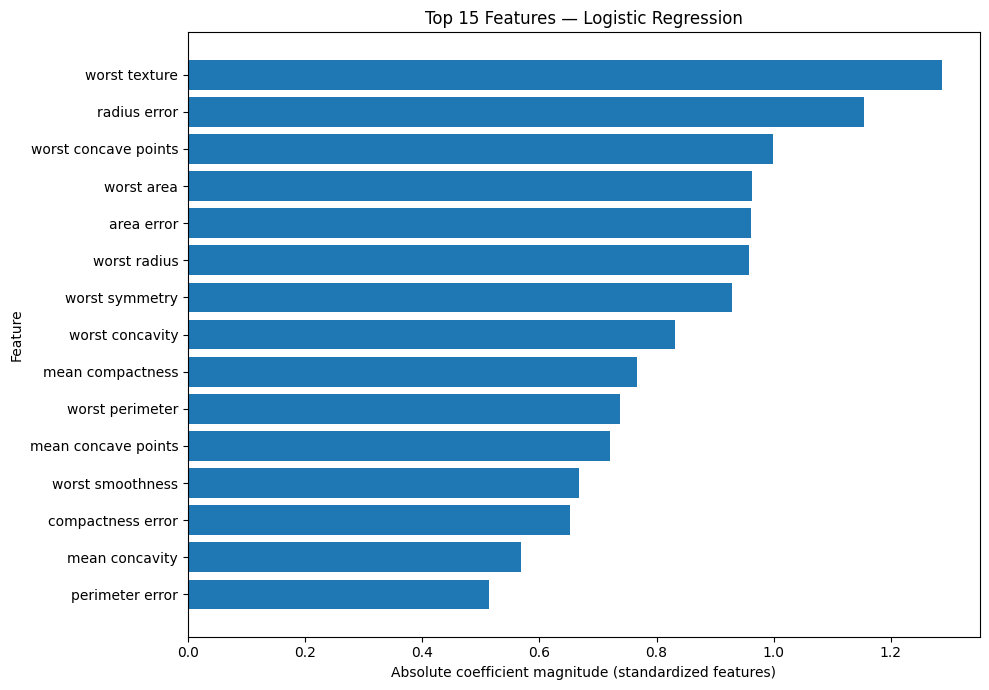

,feature,importance,signed_coefficient
21,worst texture,1.287852,-1.287852
10,radius error,1.155024,-1.155024
27,worst concave points,0.999601,-0.999601
23,worst area,0.963120,-0.963120
13,area error,0.960519,-0.960519
20,worst radius,0.957826,-0.957826
28,worst symmetry,0.929191,-0.929191
26,worst concavity,0.832080,-0.832080
5,mean compactness,0.767356,0.767356
22,worst perimeter,0.737204,-0.737204


In [7]:
if best_name=="Logistic Regression":
 coef=best_model.named_steps["model"].coef_[0]
 importance=pd.DataFrame({"feature":X.columns,"importance":np.abs(coef),"signed_coefficient":coef})
 importance_label="Absolute coefficient magnitude (standardized features)"
else:
 importance=pd.DataFrame({"feature":X.columns,"importance":best_model.feature_importances_})
 importance_label="Random-forest feature importance"
importance=importance.sort_values("importance",ascending=False).head(15)
fig,ax=plt.subplots(figsize=(10,7)); bars=importance.sort_values("importance")
ax.barh(bars.feature,bars.importance)
ax.set(title=f"Top 15 Features — {best_name}",xlabel=importance_label,ylabel="Feature")
plt.tight_layout(); plt.show()
display(importance)

## 7. Sample prediction
This function accepts one row containing all 30 numeric features. This is an educational demonstration on a public benchmark dataset, not a medical diagnostic tool.

In [8]:
def predict_sample(feature_values):
 row=pd.DataFrame([feature_values],columns=X.columns)
 label_num=int(best_model.predict(row)[0])
 return {"predicted_label":"benign" if label_num==1 else "malignant",
         "estimated_benign_probability":round(float(best_model.predict_proba(row)[0,1]),4)}
example=X_test.iloc[0]
print("Actual label:","benign" if int(y_test.iloc[0])==1 else "malignant")
print("Prediction:",predict_sample(example.to_dict()))

Actual label: malignant
Prediction: {'predicted_label': 'malignant', 'estimated_benign_probability': 0.0}


## 8. Limitations and responsible use
- This is a classic, relatively small benchmark dataset and may not represent current clinical populations.
- This model is for learning only, not diagnosis or treatment decisions.
- A random split does not replace external validation.
- Performance depends on split, preprocessing, hyperparameters, and threshold.
- Feature importance is not causal explanation. Real deployment would require clinical expertise, bias analysis, calibration, privacy controls, and regulatory review.
- Target information is not used to construct features; scaling is inside the pipeline to prevent leakage.